# Choisir une politique d'alerte par son coût

E4 compare six politiques sur 240 scénarios. Aucune ne domine sur tous les critères :
il faut **arbitrer** entre fausses pages, dégradations manquées et retard. Ce notebook
rend l'arbitrage explicite : on donne un coût à chaque type d'erreur, et on cherche la
politique et le seuil k qui minimisent le coût attendu par scénario.

Données : `results/tables/e4_results.csv` (une ligne par scénario, politique, seuil k et
lissage). Rien n'est recalculé.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from zonefleet import viz
from zonefleet.config import RESULTS
from zonefleet.labels import POLICY_COLOR, POLICY_SHORT

viz.setup()
r = pd.read_csv(RESULTS / "tables" / "e4_results.csv")
r = r[r["policy"].isin(POLICY_COLOR)]
print(r.groupby("policy").size().to_string())

policy
P1b_drift_clean      2880
P2_dle               2880
P3b_clean_and_dle    2880
P4_realized          2880


## Le modèle de coût

Par scénario :

- **fausse page** : chaque allumage d'alerte sur un jour sans dérive coûte `c_fa`
  (une nuit d'astreinte, de la confiance perdue dans le moniteur) ;
- **dégradation manquée** : un scénario nuisible non détecté dans les 28 jours coûte
  `c_miss` (des semaines de flotte mal positionnée) ;
- **retard** : chaque jour entre l'injection et la décision coûte `c_day`.

Les valeurs par défaut sont des ordres de grandeur à remplacer par ceux de ZoneFleet.

In [2]:
def expected_cost(r, c_fa=1.0, c_miss=10.0, c_day=0.3):
    d = r.copy()
    missed = d["harmful"] & ~d["detected"]
    late = np.where(d["harmful"] & d["detected"], d["delay_days"].clip(lower=0), 0.0)
    d["cost"] = c_fa * d["false_alert_events"] + c_miss * missed + c_day * late
    return d.groupby(["policy", "smooth", "k"])["cost"].mean().reset_index()


costs = expected_cost(r)
best = costs.sort_values("cost").head(8)
best.assign(policy=best["policy"].map(POLICY_SHORT)).round(3)

,policy,smooth,k,cost
24,P3b dérive nettoyée ET DLE,1,0.5,1.704
30,P3b dérive nettoyée ET DLE,7,0.5,1.725
0,P1b dérive nettoyée,1,0.5,1.872
1,P1b dérive nettoyée,1,1.0,1.872
4,P1b dérive nettoyée,1,2.5,1.872
5,P1b dérive nettoyée,1,3.0,1.872
2,P1b dérive nettoyée,1,1.5,1.872
3,P1b dérive nettoyée,1,2.0,1.872


## Le choix dépend du prix d'une fausse page

On fait varier le coût d'une fausse page de 0,1 à 20 (le coût d'une dégradation manquée
reste à 10) et on regarde quelle politique gagne.

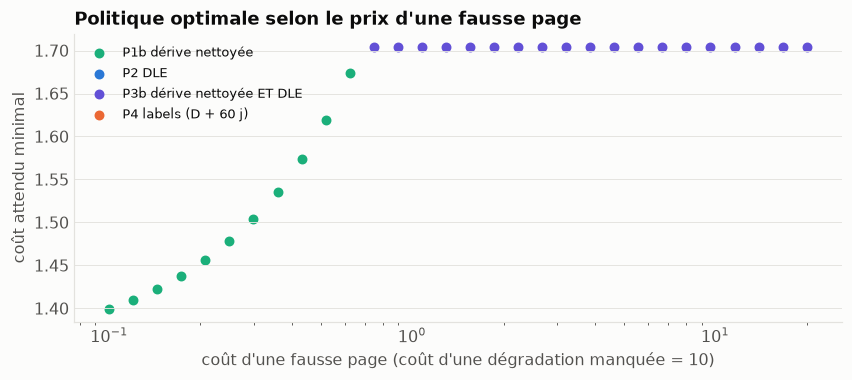

,c_fa,policy,smooth,k,cost
0,0.100,P1b_drift_clean,1,0.5,1.400
11,0.746,P3b_clean_and_dle,1,0.5,1.704


In [3]:
grid = np.geomspace(0.1, 20, 30)
winners = []
for c in grid:
    cc = expected_cost(r, c_fa=c).sort_values("cost").iloc[0]
    winners.append((c, cc["policy"], cc["smooth"], cc["k"], cc["cost"]))
w = pd.DataFrame(winners, columns=["c_fa", "policy", "smooth", "k", "cost"])
fig, ax = plt.subplots(figsize=(9, 3.4))
for pol, col in POLICY_COLOR.items():
    sub = w[w["policy"] == pol]
    ax.scatter(sub["c_fa"], sub["cost"], color=col, s=30, label=POLICY_SHORT[pol])
ax.set_xscale("log")
ax.set_xlabel("coût d'une fausse page (coût d'une dégradation manquée = 10)")
ax.set_ylabel("coût attendu minimal")
ax.set_title("Politique optimale selon le prix d'une fausse page")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()
w.drop_duplicates("policy").round(3)

## Lecture

- Tant qu'une fausse page coûte moins d'environ **0,75** (soit 7,5 % d'une dégradation
  manquée), la **dérive nettoyée seule** gagne : elle détecte le plus, quitte à alerter
  plus souvent.
- Au-delà, la **condition jointe nettoyée** devient optimale : elle ne fait jamais de
  fausse page et garde un délai de quelques jours.
- Les **labels** (P4) ne gagnent jamais : leur délai de deux mois coûte trop cher, même
  avec un coût journalier de retard modeste.

Le choix d'une politique d'astreinte n'est donc pas une question de « meilleure
méthode » mais de **prix relatif des erreurs**, à fixer avec le métier. Pour ZoneFleet,
où une nuit d'astreinte inutile coûte plus que quelques pourcents d'une semaine de flotte
mal placée, la condition jointe est le bon choix.